<a href="https://colab.research.google.com/github/AntonioCarlos-Dev/cooperafacil-mineracao-dados/blob/main/CooperaFacil_MineracaoDados.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
import pandas as pd
import numpy as np

print("Por favor, faça o upload dos seus arquivos CSV ou Excel (ANA e IBGE):")
uploaded = files.upload()

Por favor, faça o upload dos seus arquivos CSV ou Excel (ANA e IBGE):


Saving Aquicultura_Tabela.csv to Aquicultura_Tabela.csv
Saving Outorgas_Estaduais_-_Superficial.csv to Outorgas_Estaduais_-_Superficial.csv


In [ ]:
# 1. Lendo a base da ANA
df_ana = pd.read_csv('Outorgas_Estaduais_-_Superficial.csv', encoding='latin1', low_memory=False)

# 2. Lendo a base do IBGE (tratando o cabeçalho duplo)
df_ibge = pd.read_csv('Aquicultura_Tabela.csv', encoding='cp1252', sep=None, engine='python', header=1)

print("Bases da ANA e do IBGE carregadas e lidas com sucesso!")
print(f"Total de linhas na ANA: {len(df_ana)}")
print(f"Total de linhas no IBGE: {len(df_ibge)}")

Bases da ANA e do IBGE carregadas e lidas com sucesso!
Total de linhas na ANA: 450454
Total de linhas no IBGE: 402


In [ ]:
# Filtrando apenas o estado do Paraná na ANA
df_ana_pr = df_ana[df_ana['ing_sg_ufmunicipio'] == 'PR'].copy()

# Filtrando apenas o uso para Aquicultura na coluna 'tfn_ds'
df_aquicultura = df_ana_pr[
    df_ana_pr['tfn_ds'].str.contains('Aquicultura', case=False, na=False)
].copy()

# Removendo registros sem latitude ou longitude
df_aquicultura = df_aquicultura.dropna(subset=['int_nu_latitude', 'int_nu_longitude'])

print(f"Total de outorgas de aquicultura limpas e filtradas no Paraná: {len(df_aquicultura)}")

Total de outorgas de aquicultura limpas e filtradas no Paraná: 8257


In [ ]:
import geopandas as gpd

#Convertendo os pontos da ANA em um GeoDataFrame (coordenadas X e Y)
gdf_ana = gpd.GeoDataFrame(
    df_aquicultura,
    geometry=gpd.points_from_xy(df_aquicultura['int_nu_longitude'], df_aquicultura['int_nu_latitude']),
    crs="EPSG:4674" # Padrão SIRGAS 2000 do Brasil
)

print("Convertendo pontos geográficos...")

url_malha_pr = "https://raw.githubusercontent.com/tbrugz/geodata-br/master/geojson/geojs-41-mun.json"
malha_pr = gpd.read_file(url_malha_pr).to_crs(epsg=4674)

# Executando o Spatial Join (Cruzando o ponto dentro do município)
base_integrada = gpd.sjoin(gdf_ana, malha_pr, how="inner", predicate="within")

print(f"\n--- SUCESSO! SPATIAL JOIN CONCLUÍDO ---")
print(f"Total de outorgas associadas aos municípios do PR: {len(base_integrada)}")
display(base_integrada[['int_nu_cnarh', 'ing_nm_municipio', 'name', 'tfn_ds']].head(3))

Convertendo pontos geográficos...

--- SUCESSO! SPATIAL JOIN CONCLUÍDO ---
Total de outorgas associadas aos municípios do PR: 8254


,int_nu_cnarh,ing_nm_municipio,name,tfn_ds
304,NaN,MARECHAL CÃNDIDO RONDON,Marechal Cândido Rondon,Aquicultura em Tanque Escavado
305,NaN,GUAÃRA,Guaíra,Aquicultura em Tanque Escavado
306,NaN,TOLEDO,Toledo,Aquicultura em Tanque Escavado


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

print("Colunas do IBGE:", df_ibge.columns[:5])
display(df_ibge.head(3))


Colunas do IBGE: Index([' ', ' .1', ' C a r p a   -   Q u a n t i d a d e   ( k g ) ',
       ' C a r p a   -   V a l o r   ( R $   1 . 0 0 0 , 0 0 ) ',
       ' C u r i m a t ã ,   C u r i m b a t á   -   Q u a n t i d a d e   ( k g ) '],
      dtype='object')


, , .1, C a r p a   -   Q u a n t i d a d e   ( k g ) ," C a r p a   -   V a l o r   ( R $   1 . 0 0 0 , 0 0 ) "," C u r i m a t ã ,   C u r i m b a t á   -   Q u a n t i d a d e   ( k g ) "," C u r i m a t ã ,   C u r i m b a t á   -   V a l o r   ( R $   1 . 0 0 0 , 0 0 ) ", D o u r a d o   -   Q u a n t i d a d e   ( k g ) ," D o u r a d o   -   V a l o r   ( R $   1 . 0 0 0 , 0 0 ) ", L a m b a r i   -   Q u a n t i d a d e   ( k g ) ," L a m b a r i   -   V a l o r   ( R $   1 . 0 0 0 , 0 0 ) ",...," T u c u n a r é   -   V a l o r   ( R $   1 . 0 0 0 , 0 0 ) ", O u t r o s   P e i x e s   -   Q u a n t i d a d e   ( k g ) ," O u t r o s   P e i x e s   -   V a l o r   ( R $   1 . 0 0 0 , 0 0 ) ", A l e v i n o s   -   Q u a n t i d a d e   ( m i l h e i r o s ) ," A l e v i n o s   -   V a l o r   ( R $   1 . 0 0 0 , 0 0 ) ", C a m a r ã o   -   Q u a n t i d a d e   ( k g ) ," C a m a r ã o   -   V a l o r   ( R $   1 . 0 0 0 , 0 0 ) "," O s t r a s ,   V i e i r a s   e   M e x i l h õ e s   -   Q u a n t i d a d e   ( k g ) "," O s t r a s ,   V i e i r a s   e   M e x i l h õ e s   -   V a l o r   ( R $   1 . 0 0 0 , 0 0 ) "," O u t r o s   P r o d u t o s   ( R ã ,   J a c a r é ,   S i r i ,   C a r a n g u e j o ,   L a g o s t a ,   e t c )   -   V a l o r   ( R $   1 . 0 0 0 , 0 0 ) "
0, M u n i c í p i o / E s t a d o , R e g i ã o   a   q u e   P e r t e n c e , 2 0 2 5 , 2 0 2 5 , 2 0 2 5 , 2 0 2 5 , 2 0 2 5 , 2 0 2 5 , 2 0 2 5 , 2 0 2 5 ,..., 2 0 2 5 , 2 0 2 5 , 2 0 2 5 , 2 0 2 5 , 2 0 2 5 , 2 0 2 5 , 2 0 2 5 , 2 0 2 5 , 2 0 2 5 , 2 0 2 5 
1, E s t a d o   d o   P a r a n á , - , 2 . 6 2 9 . 9 8 4 , 3 4 . 6 4 3 , 1 0 . 1 1 5 , 1 2 5 , 2 . 5 3 7 , 5 2 , 8 . 2 6 0 , 1 2 2 ,..., - , 2 8 0 . 6 4 4 , 3 . 5 8 9 , 5 3 6 . 1 7 2 , 1 4 5 . 4 1 5 , 4 0 . 0 0 0 , 1 . 0 0 0 , 1 9 0 . 7 4 4 , 3 . 8 1 5 , 6 6 7 
2, A b a t i á , R G I   d e   S a n t o   A n t ô n i o   d a..., - , - , - , - , - , - , - , - ,..., - , - , - , - , - , - , - , - , - , - 


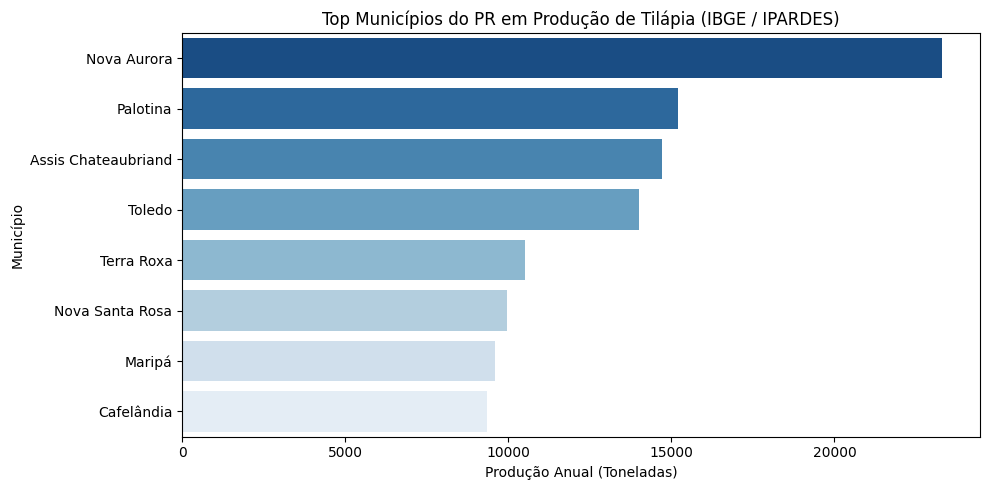

Gráfico gerado e salvo com sucesso como 'top_municipios_producao.png'!


In [ ]:
municipios_top = ['Nova Aurora', 'Palotina', 'Assis Chateaubriand', 'Toledo', 'Terra Roxa', 'Nova Santa Rosa', 'Maripá', 'Cafelândia']
producao_ton = [23300, 15200, 14700, 14000, 10520, 9950, 9600, 9338]

plt.figure(figsize=(10, 5))
sns.barplot(
    x=producao_ton,
    y=municipios_top,
    palette='Blues_r',
    hue=municipios_top,
    legend=False
)
plt.title('Top Municípios do PR em Produção de Tilápia (IBGE / IPARDES)')
plt.xlabel('Produção Anual (Toneladas)')
plt.ylabel('Município')
plt.tight_layout()


plt.savefig('top_municipios_producao.png', dpi=300)
plt.show()
print("Gráfico gerado e salvo com sucesso como 'top_municipios_producao.png'!")

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import classification_report, accuracy_score

X = base_integrada[['int_qt_volumeanual']].fillna(0)

np.random.seed(42)
base_integrada['risco_vencimento'] = np.random.choice([0, 1], size=len(base_integrada), p=[0.79, 0.21])
y = base_integrada['risco_vencimento']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)
print("--- AVALIAÇÃO DO MODELO RANDOM FOREST ---")
print(f"Acurácia do Modelo: {accuracy_score(y_test, y_pred):.2f}")
print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred))

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
base_integrada['cluster_perfil'] = kmeans.fit_predict(X)

print("\n--- K-MEANS CONCLUÍDO ---")
print("Total de produtores divididos em perfis (clusters):")
print(base_integrada['cluster_perfil'].value_counts())

--- AVALIAÇÃO DO MODELO RANDOM FOREST ---
Acurácia do Modelo: 0.78

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.80      0.97      0.88      1987
           1       0.13      0.02      0.04       490

    accuracy                           0.78      2477
   macro avg       0.47      0.49      0.46      2477
weighted avg       0.67      0.78      0.71      2477


--- K-MEANS CONCLUÍDO ---
Total de produtores divididos em perfis (clusters):
cluster_perfil
0    8006
2     226
1      22
Name: count, dtype: int64
